In [1]:
# %load_ext autoreload
# %autoreload 2


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iml.dungeon import Dungeon
from iml.agent import DungeonAgent
from iml.visualization import DungeonVisualization
from iml.dungeon_maker import make_treasure_room, make_underground_maze, make_underground_maze_with_meat



 **Group members:** Emin Cesme, Valentine Scillia, Paulina Pervukhina

 ## Part 1: Gridworld Environment

 ### 1.1 A drunken knight in a treasure room

 ### (a)

 > Implement a stochastic policy where you select actions uniformly at random.

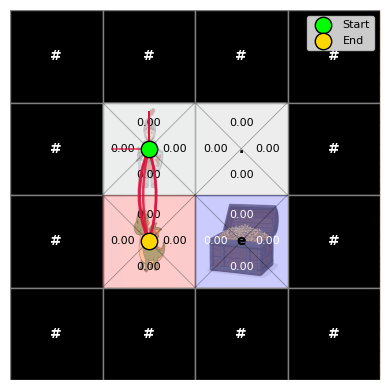

In [3]:
def my_reward_11(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_11(state, q_value):
	# <implement your action here>
	# return ... (int)
    return int(np.random.choice(4))

def my_Q_update_11(agent, state, action, reward, next_state, dungeon):
    return None # use None for now

treasure_room = make_treasure_room()
vis_11 = DungeonVisualization(treasure_room)

drunken_knight = DungeonAgent(n_states=treasure_room.n_states, choose_action=my_action_11,reward_func=my_reward_11,update_q_values=my_Q_update_11)

# Run the agent for 1 episode & collect states, actions, rewards
states, actions, rewards = drunken_knight.run_episode(treasure_room, nstep=10, gamma=1.0)

# Show the map, Q-values, and path.
vis_11.show(states, actions, drunken_knight.q_values)


 ### (b)

 > Observe how you move and draw a Markov decision process (MDP) diagram for all four non-wall states.



 ![MDP Diagram](1.1b-diagram.jpg)



 S = start, A = top-right, B = dragon, E = treasure. The reward is +1 for A → E and 0 otherwise.

 ### (c)

 > Compute the theoretical probability distribution over a 2-step horizon analytically (without writing code) when you use the stochastic policy you implemented.

 > For step 1 :

 P(s) = 1/2, P(A) = 1/4, P(B)= 1/4

 > For step 2 :



 P(s)= 1/2\*1/2+1/4\*1/4+1/4 = 9/16



 P(A)= 1/2\*1/4+1/4\*1/2 = 1/4



 P(B)= 1/2\*1/4 = 1/8



 P(e) = 1/4\*1/4 = 1/16



 All probabilities sum to 1

 ### (d)

 > If you implement Q-learning with an episode length of 1 (`nstep = 1`) under current setup, will you manage to perform better? Why or why not? Explain your reasoning.

 > No, the agent cannot improve its performance. With the corrected code (`range(nstep)`), the agent takes exactly one step per episode. However, reaching the treasure requires at least two steps, so the agent never receives a positive reward. Therefore, the Q-values remain 0, and the agent cannot learn a better policy.

 ### (e)

 > For a dungeon of width $N$ and height $M$, what is the minimum number of steps required to reach the goal from the starting position? Why?



 If $N$ and $M$ are non-wall cells and the start and treasure are in opposite corners, the minimum is $(N-1)+(M-1)$ steps.



 This is because the agent needs to move $N-1$ (whole width-1) steps in one direction and $M-1$(whole height-1) steps in the other direction to reach the goal.



 If $N$ and $M$ include a outer wall border, the interior width and height are $N-2$ and $M-2$, so the opposite interior corners are $(N-3)+(M-3)$ steps apart.



 The general formula is the manhattan distance between the start and treasure positions, which is $|x_1 - x_2| + |y_1 - y_2|$ where $(x_1, y_1)$ and $(x_2, y_2)$ are the coordinates of the start and goal positions.

 The very minimum number of steps is 1 if start ans trasure are adjacent.

 ---

 ### 1.2 A tricky knight in an underground maze



 ### (a)

 > (a) Using your stochastic policy $\pi$, implement the Q-learning update with a discount factor ($\gamma = 1$) and a maximum episode length of 30 steps ($n_{\text{step}} = 30$). Run consecutive episodes without resetting the Q-table. Explain your observations on how the Q-values change relative to the goal and starting locations.



 During training, the Q-values near the trasure increase first becausethese states receive the reward more directly.



 As training continues, the reward information propagates backward toward the starting position.



 Since the agent follows a random policy, its actions do not necessarily improve, even when its Q-values become more accurate.

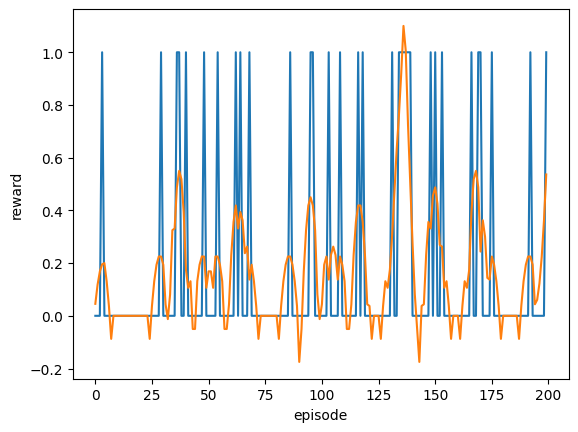

Episode 1
Q-values at start: [0. 0. 0. 0.]
Episode 50
Q-values at start: [0.02398106 0.01053827 0.00343591 0.01177173]
Episode 200
Q-values at start: [0.90355106 0.89252878 0.86400537 0.8889471 ]


In [4]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_12(state, q_values):
    return np.random.choice(4) 

alpha = 0.1
gamma = 1.0

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
    future_value = (
        0.0 if next_state == dungeon.end
        else np.max(agent.q_values[:, next_state])
    )

    old_value = agent.q_values[action, state]
    target = reward + gamma * future_value
    agent.q_values[action, state] = old_value + alpha * (target - old_value)


underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, choose_action=my_action_12, reward_func=my_reward_12, update_q_values=my_Q_update_12)

training_reward = []
# program your knight here
# compute episodic reward
# append "training_reward"
q_snapshots = {}
np.random.seed(12)  # For reproducibility

for episode in range(200):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=1.0)
    training_reward.append(sum(rewards))
    if episode in (0,49,199):
        q_snapshots[episode+1] = tricky_knight.q_values.copy()

# plot "training_reward"
vis_12.plot_training_reward(training_reward)
for episode, q_values in q_snapshots.items():
    print(f"Episode {episode}")
    print("Q-values at start:", q_values[:, underground_maze.start])


 ### (b)

 > By varying the discount factor $\gamma$, do you observe any differences? Summarize how the discount rate affects the results and explain why it is necessary.

 Gamma controls how much the knight cares about future rewards. (1 = cares abt future, 0 = cares abt immediate).

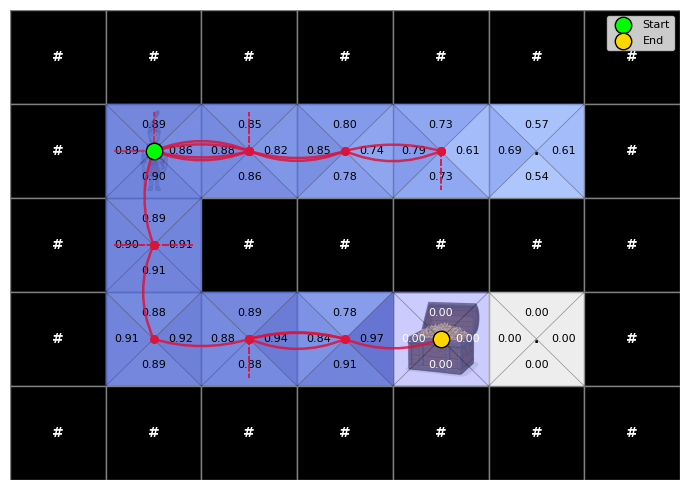

Gamma = 1.0
Q-values at start: [0.90355106 0.89252878 0.86400537 0.8889471 ]


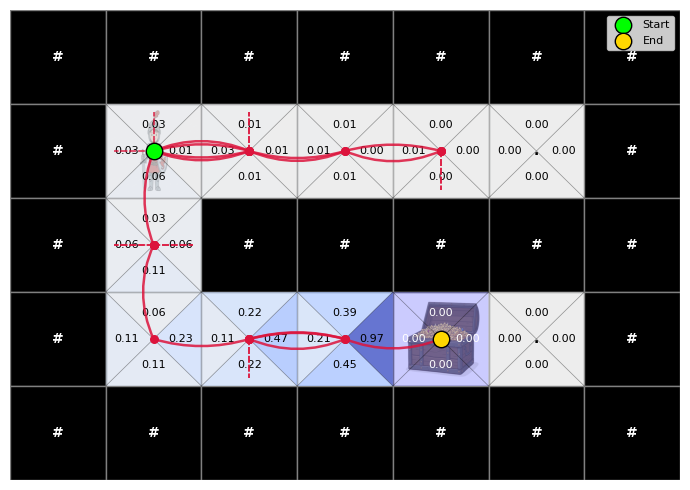

Gamma = 0.5
Q-values at start: [0.05647194 0.02789152 0.01350008 0.0277796 ]


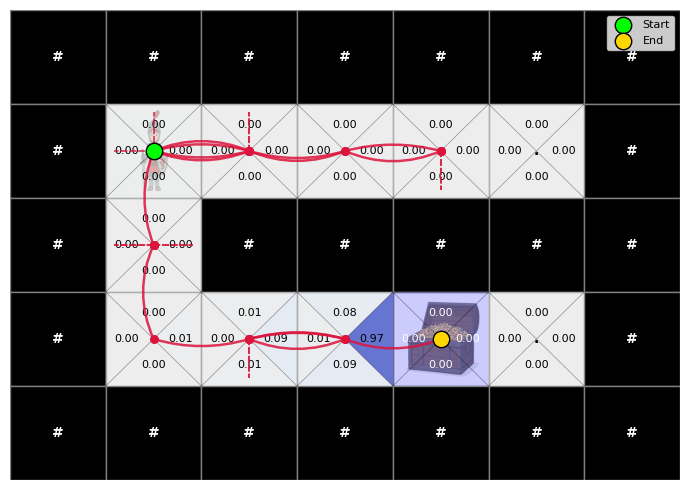

Gamma = 0.1
Q-values at start: [9.03551062e-05 8.92528785e-06 8.64005367e-07 8.88947098e-06]


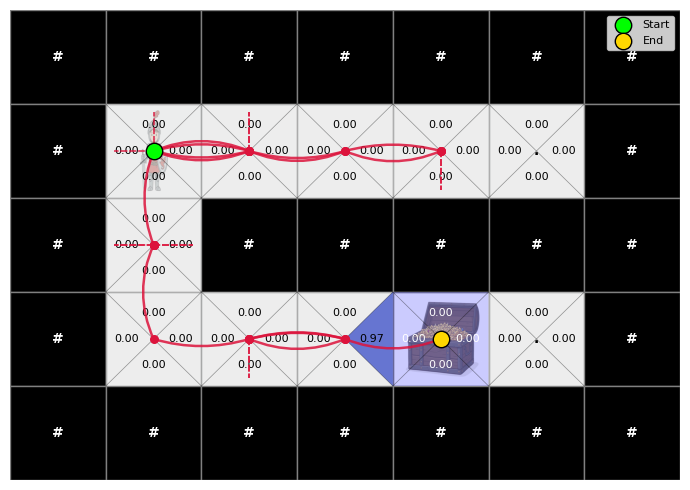

Gamma = 0.0
Q-values at start: [0. 0. 0. 0.]


In [5]:
gammas  = [1.0, 0.5, 0.1, 0.0]

for gamma in gammas: 
    np.random.seed(12)
    knight = DungeonAgent(n_states=underground_maze.n_states, choose_action=my_action_12, reward_func=my_reward_12, update_q_values=my_Q_update_12)
    training_reward = []
    for episode in range(200):
        states, actions, rewards = knight.run_episode(underground_maze, nstep=30, gamma=gamma)
        training_reward.append(sum(rewards))
    vis_12.show(states, actions, knight.q_values)
    print(f"Gamma = {gamma}")
    print("Q-values at start:", knight.q_values[:, underground_maze.start])

 $\gamma$ = 1.0 : future rewards are not discounted.Q-values can propagate from treasure back to start.

 $\gamma$ = 0.5 : future rewards are discounted by half each step. Q-values are lower and propagate less far back to start.

 $\gamma$ = 0.1 : future rewards are heavily discounted. Q-values are very low and only propagate a few steps back.

 $\gamma$ = 0.0 : future rewards are ignored. Q-values are zero except for immediate rewards at the treasure. The knight only learns about immediate rewards and does not plan ahead.

 The discount factor is important, because it controles how much future rewards contribue to Q-values.

 ### (c)

 > Implement an $\epsilon$-greedy policy for your agent by varying $\epsilon$. Plot the sum of discounted rewards per episode over 100 training runs and explain your observations.

 The parameter $\epsilon$ controls the balance between exploration and exploitation.



 A low $\epsilon$ means the agent chooses action with higuest Q-value. It exploits current knowledge.



 A high $\epsilon$ means the agent explores more frequently but also makes random moves.



 An intermediate $\epsilon$ balances exploration and what he has learned.



 A $\epsilon$ -greedy policy helps agent discover useful actions while benefiting from learned Q-values.



 In our run, epsilon = 0, 0.2 and 0.5 reached the treasure in 96/100 episodes, 0.8 in 72/100, and 0.99 and 1.0 only in about 25/100. Lower epsilon works best here since ties between equal Q-values are broken randomly, even epsilon = 0 explores at the start. With a high epsilon, the knight moves randomly and often runs out of steps.

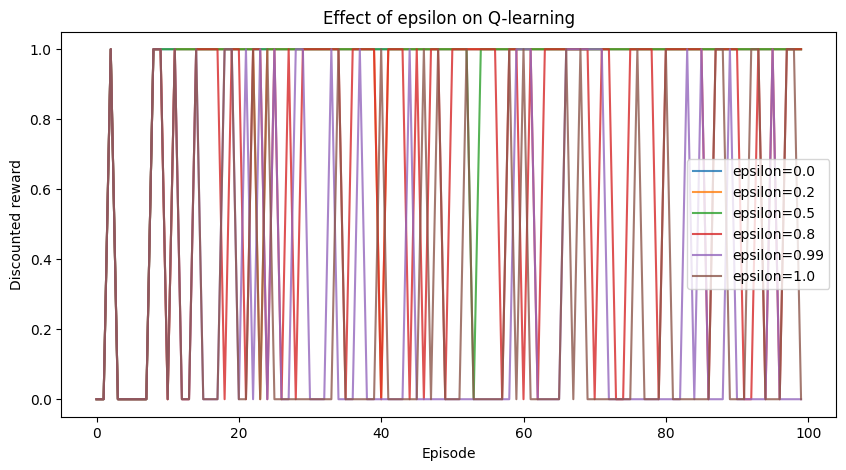

Epsilon = 0.0


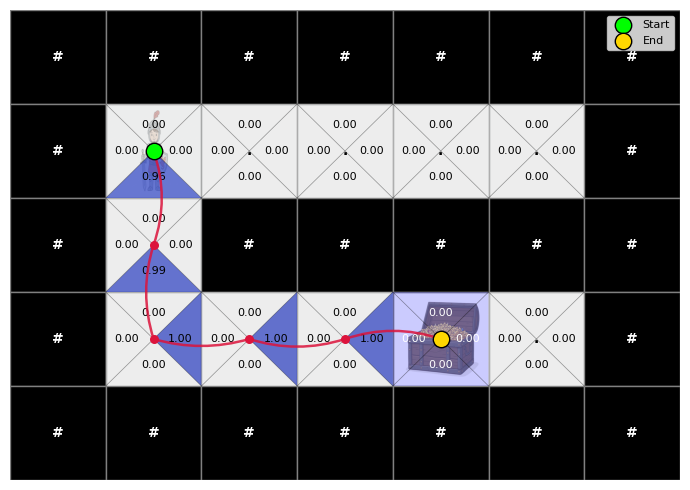

Epsilon = 0.5


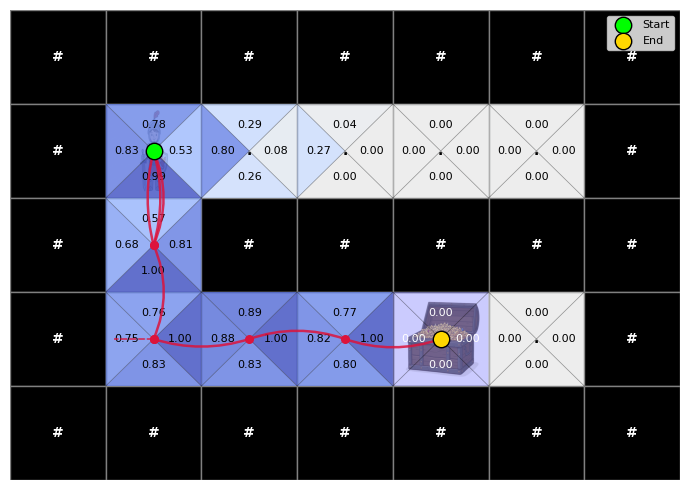

Epsilon = 1.0


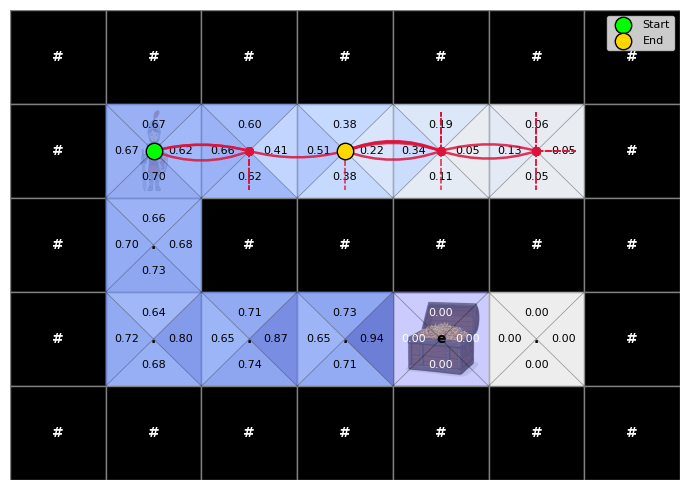

Epsilon = 0.0: 93/100 successes
Epsilon = 0.2: 90/100 successes
Epsilon = 0.5: 92/100 successes
Epsilon = 0.8: 68/100 successes
Epsilon = 0.99: 28/100 successes
Epsilon = 1.0: 26/100 successes
Best epsilon  =  0.0


In [6]:
def make_epsilon_policy(epsilon):
    def choose_action(state, q_values):
        if np.random.random() < epsilon:
            return int(np.random.choice(4))

        values = q_values[:, state]
        best_actions = np.flatnonzero(values == np.max(values))
        return int(np.random.choice(best_actions))

    return choose_action


def make_q_update(gamma):
    def update(agent, state, action, reward, next_state, dungeon):
        old_value = agent.q_values[action, state]

        if next_state == dungeon.end:
            future_value = 0.0
        else:
            future_value = np.max(agent.q_values[:, next_state])

        target = reward + gamma * future_value

        agent.q_values[action, state] = (
            old_value + alpha * (target - old_value)
        )

    return update


alpha = 0.1
gamma = 1.0
epsilons = [0.0, 0.2, 0.5, 0.8, 0.99, 1.0]

results_c = {}
snapshots_c = {}

for epsilon in epsilons:
    np.random.seed(12)

    knight = DungeonAgent(
        n_states=underground_maze.n_states,
        choose_action=make_epsilon_policy(epsilon),
        reward_func=my_reward_12,
        update_q_values=make_q_update(gamma)
    )

    training_reward = []

    for episode in range(100):
        states, actions, rewards = knight.run_episode(
            underground_maze, nstep=30, gamma=gamma
        )
        training_reward.append(sum(rewards))

    results_c[epsilon] = training_reward
    snapshots_c[epsilon] = (
        states.copy(), actions.copy(), knight.q_values.copy()
    )

# Plot discounted reward per episode
plt.figure(figsize=(10, 5))

for epsilon, rewards in results_c.items():
    plt.plot(rewards, label=f"epsilon={epsilon}", alpha=0.8)

plt.xlabel("Episode")
plt.ylabel("Discounted reward")
plt.title("Effect of epsilon on Q-learning")
plt.legend()
plt.show()

# Show 3 selected snapshots
for epsilon in [0.0, 0.5, 1.0]:
    states, actions, q_values = snapshots_c[epsilon]
    print(f"Epsilon = {epsilon}")
    vis_12.show(states, actions, q_values)

# Which epsilon performed best : 
for epsilon, rewards in results_c.items():
    successes = sum(r > 0 for r in rewards)
    print(f"Epsilon = {epsilon}: {successes}/100 successes")

best_epsilon = max(results_c,key=lambda e: sum(r>0 for r in results_c[e]))
print("Best epsilon  = ",best_epsilon)


 The best epsilon in this experiment is the one with highest number of succesful episodes.



Lower epsilon favors exploitation, while higher favors exploration.

 ### (d)

 > Is a single training run sufficient to evaluate and compare an agent’s performance across different hyperparameter settings? Specifically: (i) Will an agent reach the goal on every evaluation episode? Explain why or why not. (ii) Under what specific conditions would RL training and evaluation results be strictly deterministic and reproducible? And (iii) Given these factors, how should an RL agent's performance be properly evaluated and compared, both when those deterministic conditions are met and when they are not?



 (i) No, with a stochastic policy, the agent can choose random actions and may fail to reach the treasure within the episode.



 (ii) Results are deteministic when startiting conditions, environement, transitions... are deterministic. Using fixed random seeds also makes stochastic experiments reproducible, assumning same environment.



 (iii) For stochastic experiments, mulitple independent trials using different seeds and compare the average reward, success rate and variability. For a determinsitic experiment, repeated runs under identical conditions should produce identical outputs.

 ### (e)

 > Recreate the maze using `make_underground_maze_with_meat()`, update the reward function, set $\epsilon = 0.9$, $n_{\text{step}} = 50$, and $\gamma = 0.95$, and run the agent for 100 to 200 training runs. Explain your observations regarding your strategy (Q-values) and behavior.

 > The agent is trained for 200 episodes using $\epsilon = 0.9$, episode length of 50, and $\gamma = 0.95$.



 The treasure gives a reward of +1 while meat gives +0.5 when agent enters or stays on the cell. Because it can be collected repeatedly, the agent can obtain a total reward by staying on the meat instead of looking for trasure.



 This is called reward hacking : the agent maximises the reward fincion without completing the intiial objective.



 Here, $\epsilon = 0.9$, so the agent explores randomly most of the time, so the path may vary between episodes.

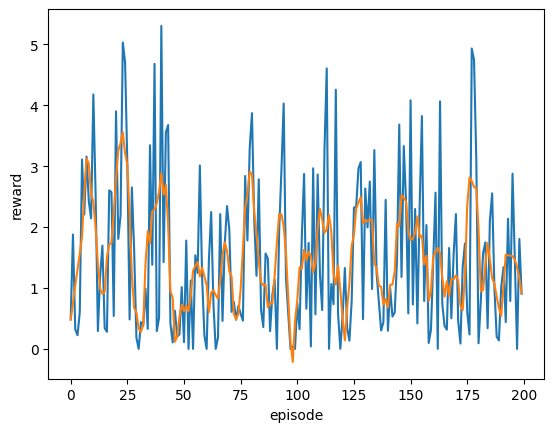

Final Q-values:


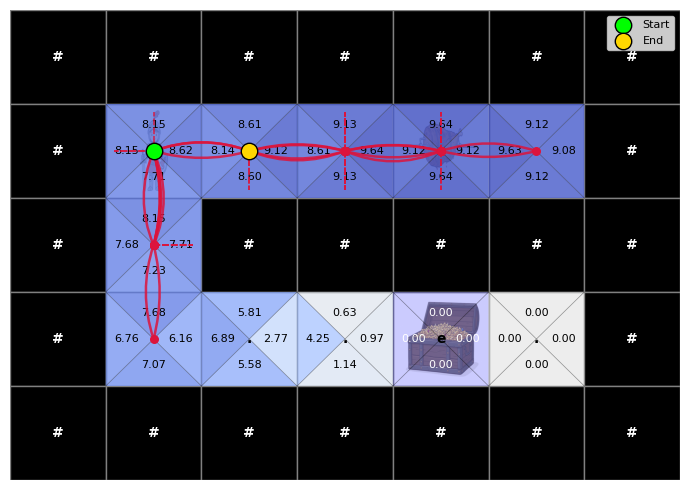

In [7]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    if dungeon.tiles[next_state] == "+":
        return 0.5
    return 0.0

epsilon = 0.9
def my_action_12(state, q_values):
	# <implement your action here>
	# return ... (int)
    if np.random.random() < epsilon:
        return int(np.random.choice(4))
    else : 
        return (int(np.argmax(q_values[:, state])))

alpha = 0.1
gamma = 0.95

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
	# <implement your Q update here>
	# Hint: lecture 9, page 18 <20/29>
	# return ... (float)
    old_value = agent.q_values[action, state]
    if next_state == dungeon.end:
        future_value = 0.0
    else:
        future_value = np.max(agent.q_values[:, next_state])
    target = reward + gamma * future_value
    agent.q_values[action, state] = old_value + alpha * (target - old_value)


underground_maze = make_underground_maze_with_meat(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, choose_action=my_action_12, reward_func=my_reward_12, update_q_values=my_Q_update_12)

training_reward = []
# program your knight here
# compute episodic reward
# append "training_reward"
np.random.seed(12)
for episode in range(200):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=50, gamma = 0.95)

    training_reward.append(sum(rewards))
# plot "training_reward"
vis_12.plot_training_reward(training_reward)
print("Final Q-values:")
vis_12.show(states, actions, tricky_knight.q_values)


 The learned Q-values favor actions that lead to the meat because the reward of +0.5 can be collected repeatedly.



 This can make staying near the meat more valuable than reaching the treasure.



 However, with $\epsilon = 0.9$, the agent takes random actions most of the time, so the path may vary between episodes.

 > (f) Compare the state values $V(s)$ when you go directly to the treasure (e), collects free meat as you observed (+), or do both. Explain your results mathematically.

 We compare the 3 strategies using this return formula :

 $$V(s) = \sum_{t=0}^{T-1}\gamma^t r_t,\qquad \gamma=0.95$$

 1. Directly to treasure : the knight reaches the treasure after 5 moves.

 $$V_1=0.95^4\approx0.8145$$

 2. Repeatedly collecting meat : the knight reaches the meat after 3 moves and can collect +0.5 repeatedly by staying on that cell. Over 49 moves :

 $$V_2=0.5\sum_{t=2}^{49}0.95^t\approx8.2151$$

 3. Meat and then treasure : the knight collects meat on move 3 and reaches the treasure on move 11.

 $$V_3=0.5(0.95^2)+0.95^{10}\approx1.0500$$

 Therefore =

 $$\boxed{V_2>V_3>V_1}$$

 Repeated meat collection gives the highest discounted return. This shows that the agent can maximize its reward without reaching the treasure, which is an example of reward hacking.

 > (g) How might you modify the reward function or environment design to prevent this *reward hacking*? Propose and explain a solution. (Bonus)

 > To prevent reward hacking, we could make the meat reward available only once per episode.

 After the knight collects the meat, it disappears or stops giving rewards. This prevents the agent from repeatedly earning +0.5 by staying on the same square.

 We could also add a small penalty for each move to discourage unnecessarily long paths.

 These changes would encourage the agent to reach the treasure instead of exploiting the meat reward.

 ## Part 2: Bayesian Decision-Making in Multi-Armed Bandits

 ### 2.1 Bayesian Estimation of Arm Rewards

 ### (a)

 > Starting from Bayes' theorem and the Bernoulli likelihood, derive the posterior distribution $p(\theta \mid D)$ and identify its updated parameters. Hence, show that the Beta distribution is a conjugate prior to the Bernoulli likelihood.

 As stated in the instructions, the posterior distribution is:



 $$ p(\theta\mid\text{D}) = \dfrac{p(\theta)\,p(\text{D}\mid\theta)}{p(\text{D})}$$



 for the likelihood: $D$ is $s$ successes and $f$ failures but all the pulls are conditionally independent given $\theta$ which means that the likelihood is just the product of all the individual probabilities which follow Bernoulli's distribution. So we get:



 $$  p(D\mid\theta) =  \theta^{s}(1-\theta)^{f} $$



 Now we look at the prior $p(\theta)$ :



 $$ p(\theta) = \dfrac{1}{B(\alpha,\beta)}\theta^{\alpha-1}(1-\theta)^{\beta-1}$$



 This means that:



 $$ p(\theta)p(D\mid\theta) = \dfrac{1}{B(\alpha,\beta)}\theta^{\alpha-1}(1-\theta)^{\beta-1} * (\theta^{s}(1-\theta)^{f})



 = \dfrac{1}{B(\alpha,\beta)}\theta^{\alpha-1+s}(1-\theta)^{\beta-1+f}$$



 Since $p(D)$ and $\dfrac{1}{B(\alpha,\beta)}$ both do not depend on $\theta$, we can say that:



 $$ p(\theta\mid\text{D}) \propto \theta^{\alpha-1+s}(1-\theta)^{\beta-1+f} $$



 please note that $\propto$ means that the left expression is proportional to the right: it is equal up to a factor that doesn't depend on our variable $\theta$



 this can be re-written as a $\theta^{(\alpha+s)-1}(1-\theta)^{(\beta+f)-1}$ which is a Beta density: $\text{Beta}(\alpha + s, \beta + f)$



 so $$\theta\mid D\sim\text{Beta}(\alpha+s,\beta+f)$$



 The posterior is, therefore, a Beta distribution which is the same distribution as the prior which means that the Beta distribution is a conjugate prior to the Bernoulli likelihood.

 ### (b)

 > Suppose the prior is $(\beta(2,2))$. After ten pulls, the arm produces seven successes and three failures. Compute the posterior distribution and posterior mean. Show that, in general, the posterior mean can be expressed as a weighted average of the prior mean and the empirical success rate. Interpret the weights and explain how they change as the number of observations increases

 So the prior is $\text{Beta}(2,2)$, $s=7$ and $f=3$. Using (a) we know that the posterior is:



 $$ \theta\mid D\sim\text{Beta}(2+7,\;2+3)=\text{Beta}(9,5) $$



 the mean for $Beta(\alpha + s, \beta + f)$ is $E[\theta\mid D]=\dfrac{\alpha + s }{\alpha + s + \beta + f}$ so here we get:



 $E[\theta\mid D] = \dfrac{9}{9+5}=\dfrac{9}{14}\approx 0.643$



 To find the weighted average we need to rewrite $E[\theta\mid D]$:



 $$ E[\theta\mid D] = \dfrac{\alpha + s }{\alpha + \beta + s + f} = \dfrac{\alpha}{\alpha + \beta + s + f} + \dfrac{s}{\alpha + \beta + s + f} = \dfrac{\alpha + \beta}{\alpha + \beta + s + f} * \dfrac{\alpha}{\alpha + \beta} + \dfrac{s + f}{\alpha + \beta + s + f} * \dfrac{s}{s + f}$$



 $\dfrac{\alpha}{\alpha + \beta}$ is the prior mean and $\dfrac{s}{s + f}$ is the success rate which are respectively $0.5$ and $0.7$.



 This is a weighted average because both weights add up to 1: $\dfrac{\alpha + \beta}{\alpha + \beta + s + f} + \dfrac{s + f}{\alpha + \beta + s + f} = \dfrac{\alpha + \beta + s + f}{\alpha + \beta + s + f} = 1$



 with our numbers we get:



 $$  E[\theta\mid D] = \tfrac{4}{14} * 0.5 + \tfrac{10}{14} * 0.7 = \tfrac{9}{14}$$



 same result as before so it is correct



 Let's look at the weights for both the prior mean and the success rate:



 The weight of the prior mean we can see as imaginary number of pulls from the prior while the weight of the success rate is the number of real pulls.



 we can clearly see that the weight of the prior mean: $\dfrac{\alpha + \beta}{\alpha + \beta + s + f}$ goes to 0 as the number of pulls increases: the numerator doesn't change as alpha and beta are constants but the denominator increases since s+f increases no matter if we win or lose.



 However, the weight of the success rate: $\dfrac{s + f}{\alpha + \beta + s + f}$ will keep increasing as the number of pulls increases: both the numerator and denominator increase at the same rate, it will tend to 1 as s+f tend to $\infty$.



 This means that, the more pulls we make, the less weight the prior mean has and the more weight the success rate has.

 ### 2.2 Learning with Thompson Samplin

 ### (a)

 > Implement a five-armed Bernoulli bandit environment that generates binary rewards using the given success probabilities. Then implement a Thompson sampling agent that maintains the posterior parameters for each arm, selects actions using posterior sampling, and updates the corresponding posterior after receiving each reward.

In [8]:
import numpy as np

n = 5
true_prob = [0.15, 0.35, 0.55, 0.65, 0.80]

def bandit(arm):
    num = np.random.rand()
    if num < true_prob[arm]: #success
        return 1
    else: #fail
        return 0

def thompson_sampling(decisions, alpha0=1.0, beta0=1.0):
    alpha = np.full(n, alpha0)
    beta = np.full(n, beta0)

    alpha_hist = [alpha.copy()]
    beta_hist = [beta.copy()] 
    arms = []

    for i in range(decisions):
        s = np.random.beta(alpha, beta)
        arm = np.argmax(s)
        reward = bandit(arm)

        if reward == 1:
            alpha[arm] += 1
        else:
            beta[arm] += 1

        arms.append(arm)
        alpha_hist.append(alpha.copy())
        beta_hist.append(beta.copy())

    alpha_hist = np.array(alpha_hist)
    beta_hist = np.array(beta_hist)
    post_mean = alpha_hist/(alpha_hist + beta_hist) 

    return alpha_hist, beta_hist, post_mean, np.array(arms)


np.random.seed(0)
decisions = 2000

alpha_hist, beta_hist, post_mean, arms = thompson_sampling(decisions)
print("Final posterior means (success probabilities): ", np.round(post_mean[-1], 3))
print("Pulls per arm:", np.bincount(arms, minlength=n))




Final posterior means (success probabilities):  [0.222 0.333 0.444 0.625 0.801]
Pulls per arm: [   7   10   16   70 1897]


 ### (b)

 > Using the results from part (a), plot the evolution of the posterior mean estimates for all five arms as a function of time; visualize the posterior distributions; discuss how the posterior means and distributions evolve; and explain why some arms become more certain about their estimated success probabilities than others.

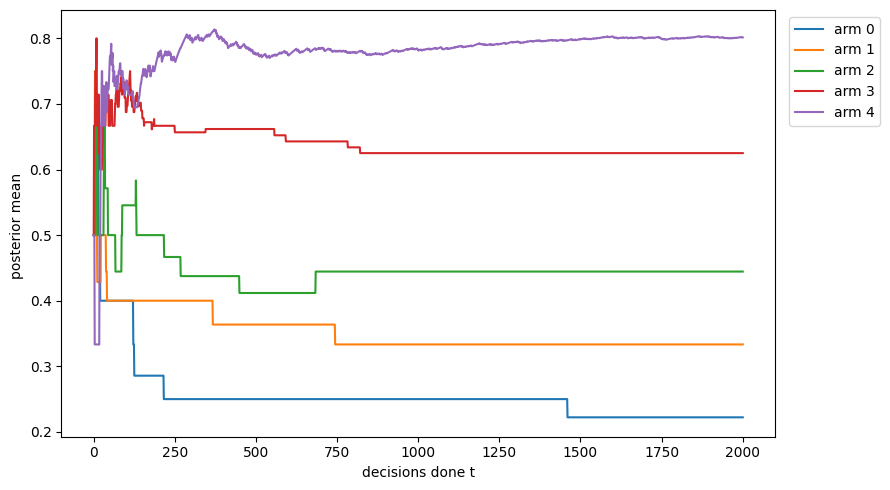

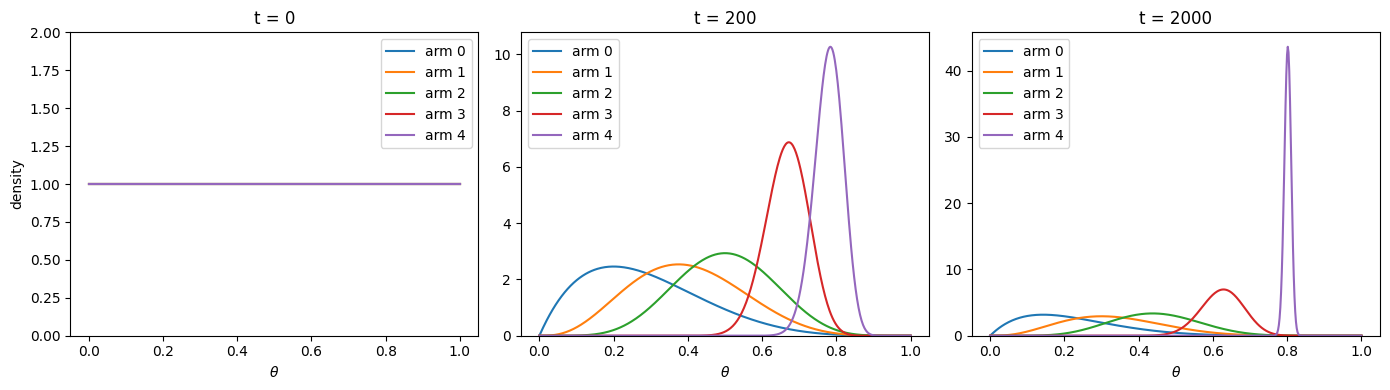

In [9]:
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist
plt.figure(figsize=(9, 5))
for i in range(n):
    plt.plot(post_mean[:, i], label=f"arm {i}")
plt.xlabel("decisions done t")
plt.ylabel("posterior mean ")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

x = np.linspace(0, 1, 500)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, t in zip(axes, [0, 200, 2000]):
    for i in range(n):
        al, be = alpha_hist[t, i], beta_hist[t, i]
        ax.plot(x, beta_dist.pdf(x, al, be), label=f"arm {i}")
    ax.set_ylim(bottom=0, top=2 if t == 0 else None)
    ax.set_title(f"t = {t}")
    ax.set_xlabel("$\\theta$")
    ax.legend()
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()


 the posterior means all start by being very imprecise and they only settle by the end. We can see that arm 4 is the only one that wobbles at the end, this means that it is the only one getting pulled by the end (almost entirely). We also see that that arm converges to its actual value ($0.8$) while the others can't anymore since they are not getting pulled.





 when $t=0$ all arms have the same $\text{Beta}(1,1)$ and the same posterior mean $0.5$ this is why they all look identical.



 when $t=200$ the difference between the arms can be seen. Arm 4 already has the most narrow peak getting close to $0.8$ and arm 3 follows right after, it is not as close as arm 4 but it still shows a pretty good estimate.



 when $t=2000$ arm 4 is even more precise to $0.8$, arm 3 doesn't seem to have narrowed much and arm 0, 1 and 2 are very wide and low, they didn't move much between t=200 and t=2000.





 This is all because, arm 4 was the most pulled one as its posterior samples were the highest most of the times, and with each pull, the estimation gets better and that is why the curve is more narrow. This also means that it will keep getting chosen most of the time and the lower arms like 1 will almost never get picked, this is why they stay very wide, the estimation cannot be precise because the arm wasn't pulled enough. On a side note, this isn't a problem because the agent doesn't need to know how bad an arm is, it just needs to know that it is bad. So even if they are not precise, if they are flagged as bad it doesn't matter much.

 ### 2.3 Experimental Evaluation and Exploration

 ### (a)

 > Perform 100 independent trials of Thompson sampling, each consisting of 2,000 decisions. Initialize a new agent with the same priors at the beginning of every trial.

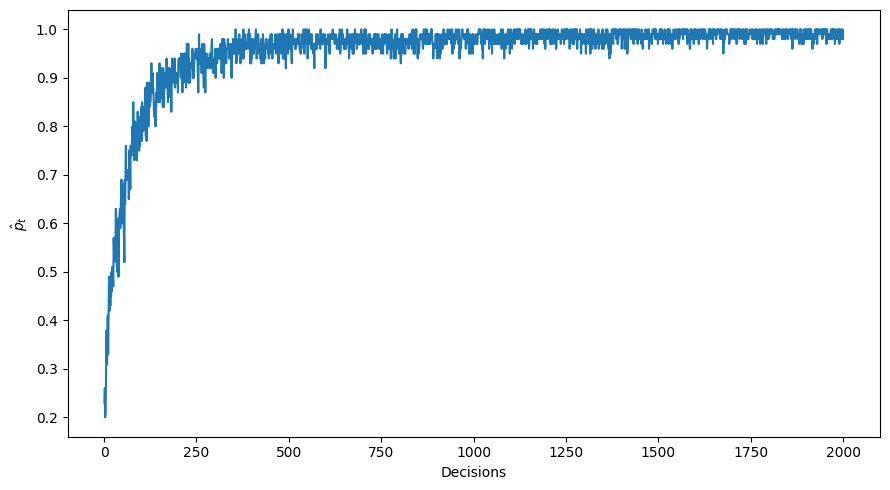

In [10]:
best = np.argmax(true_prob)
n_trials = 100

chose_best = np.zeros((n_trials, decisions))

for j in range(n_trials):
    _, _, _, arms_j = thompson_sampling(decisions)
    chose_best[j] = (arms_j == best)

p_hat = chose_best.mean(axis=0)

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, decisions + 1), p_hat)
plt.xlabel("Decisions")
plt.ylabel("$\\hat{p}_t$")
plt.tight_layout()
plt.show()


 At the beginning (when $t=1$) $\hat{p}_t$ is about 0.2 which means that the best arm is chosen only one fifth of the time. This is expected since there are 5 arms and that they all have the same prior: the choice is random and we are exploring.



 Then, as t increases (the amount of decisions), $\hat{p}_t$ approaches 1 quickly at first and then slowly. Indeed, at around $t=250$ $\hat{p}_t$ is already pretty close to 1 (about 0.95) and when $t=500$, $\hat{p}_t$ is almost 1 and the graph is getting very flat.



 However, the graph approaches 1 but stays slightly below it on average, this is because exploration is never entirely stopped, it is highly reduced with time but occasionally the model will still select an arm with a lower posterior mean when it is uncertain enough.



 $\hat{p}_t$ increases because with more data, the agent gets a better estimation of which arm will give the highest reward and they will choose that arm more often.

 ### (b)

 > Derive the agent's expected reward per decision and its expected instantaneous pseudo-regret. Hence, derive the expected cumulative pseudo-regret $\mathbb{E}[\mathcal{R}_T]$. How does it grow with $T$, assuming $\epsilon$ remains fixed and the greedy choice remains optimal? (Bonus)

 !!! on the pdf this is question 2.3 c.



 $K$ is the number of arms, $A_t$ is the arm selected at decision $t$ and $\theta^*=\max_i\theta_i$, the optimal expected reward per decision. We set $\bar\theta=\frac1K\sum_i\theta_i$ as the average arm value since each arm has a probability $\frac1K$ to be selected and a reward $\theta_i$





 For each decision, the agent has two possibilities: with probability $1-\epsilon$ it selects the optimal arm with reward $\theta^*$ and with probability $\epsilon$ it explores: selects a random arm. Each arm has probability $\frac1K$ to be chosen and reward $\theta_i$





 So, we multiply the probability with the expected reward:



 $$ E[\theta_{A_t}] = (1-\epsilon) * \theta^* + \epsilon * \frac1K\sum_i\theta_i = (1-\epsilon) * \theta^* + \epsilon * \bar\theta

 $$

 This is the expected reward per decision.



 The expected instantaneous pseudo-regret is simply this subtracted from $\theta^*$:

 $$ E[\theta^* - \theta_{A_t}] = \theta^* - ((1-\epsilon) * \theta^* + \epsilon * \bar\theta) = \theta^* - (1-\epsilon) * \theta^* - \epsilon * \bar\theta = \epsilon*\theta^* - \epsilon * \bar\theta = \epsilon(\theta^* - \bar\theta)

 $$



 Each decision will have the same regret since $\epsilon$, $\theta^*$ and $\bar\theta$ don't depend on $t$. So to know the expected cumulative pseudo-regret for T decisions we just need to add the regret T times:

 $$ E[\mathcal R_T]=T*\epsilon*(\theta^*-\bar\theta)

 $$



 Assuming $\epsilon$ remains fixed, $E[\mathcal R_T]$ grows linearly with $T$

 ### (c)

 > Compare $\epsilon$-greedy exploration with Thompson sampling. Explain why Thompson sampling may select an arm with a lower posterior mean and how its exploration behavior changes as more observations accumulate.

 !!! on the pdf this is question 2.3 b.



 $\epsilon$-greedy picks, with probability $1-\epsilon$, the arm with the highest estimate and, with probability $\epsilon$, one arm at random (it can still be the one with the highest estimate with the same probability as it could be the one with the worst estimate).

 With $\epsilon$ not changing, it will explore at the same rate, unlike Thompson sampling, which changes the exploration rate with how confident it is of the estimates.



 With Thompson sampling, the agent draws one random sample from the posterior of each arm and pulls the arm with the highest sample. An arm that hasn't been pulled much has a wide posterior, so its samples are much more spread out than those of an arm that has been pulled a lot, whose samples stay close to its mean. This means that the sample of an uncertain arm can sometimes land higher than the sample of the best arm, and then this is the arm that is pulled. Therefore, Thompson sampling might select an arm with a lower posterior mean.



 When an arm is pulled, its posterior gets more narrow, which means that the posteriors of the arms stop overlapping each other as much. At some point, a bad arm's posterior doesn't overlap with the good arm's anymore and, when that happens, its sample almost never wins and that arm is almost never chosen again. This means that exploration decreases over time. At the beginning, all the posteriors overlap, so the arms are chosen almost at random, but with time the posteriors get narrower and separate from each other, and the best arm is chosen almost every time, so exploration is almost non-existent.